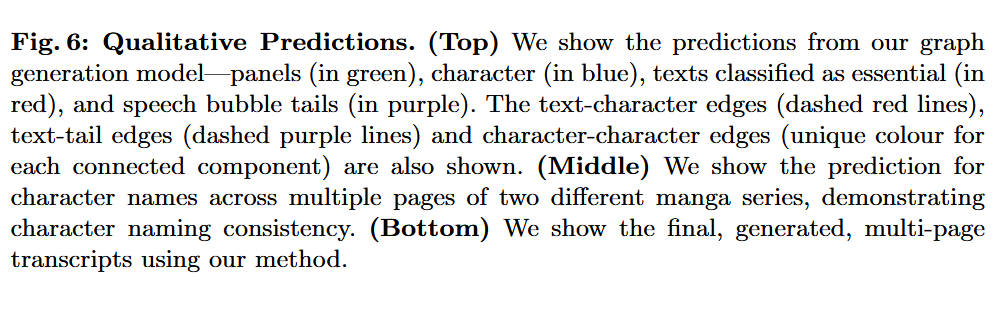

In [1]:
from PIL import Image
import numpy as np
from transformers import AutoModel
import torch
from pathlib import Path

model = AutoModel.from_pretrained("C:\MODELS\magiv2", trust_remote_code=True).cuda().eval()


def read_image(path_to_image):
    with open(path_to_image, "rb") as file:
        image = Image.open(file).convert("L").convert("RGB")
        image = np.array(image)
    return image

root = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc')
chapter_pages = [root/"01.png", root/"02.png", root/"03.png"]
character_bank = {
    "images": [],
    "names": []
}

chapter_pages = [read_image(x) for x in chapter_pages]

with torch.no_grad():
    per_page_results = model.do_chapter_wide_prediction(chapter_pages, character_bank, use_tqdm=True, do_ocr=True)

transcript = []
for i, (image, page_result) in enumerate(zip(chapter_pages, per_page_results)):
    model.visualise_single_image_prediction(image, page_result, f"page_{i}.png")
    speaker_name = {
        text_idx: page_result["character_names"][char_idx] for text_idx, char_idx in page_result["text_character_associations"]
    }
    for j in range(len(page_result["ocr"])):
        if not page_result["is_essential_text"][j]:
            continue
        name = speaker_name.get(j, "unsure") 
        transcript.append(f"<{name}>: {page_result['ocr'][j]}")
with open(f"transcript.txt", "w") as fh:
    for line in transcript:
        fh.write(line + "\n")


<>:7: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
<>:7: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
C:\Users\ESHAAN\AppData\Local\Temp\ipykernel_34764\1699127901.py:7: SyntaxWarning: "\M" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\M"? A raw string is also an option.
  model = AutoModel.from_pretrained("C:\MODELS\magiv2", trust_remote_code=True).cuda().eval()


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\module.py:2593: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  module._load_from_state_dict(
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\batchnorm.py:141: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  super()._load_from_state_dict(
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\batchnorm.py:141: UserWarning: for bn1.bias: copying fr

In [12]:
a = transcript
len(a)

27

In [5]:
page_result.keys()

dict_keys(['panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text', 'ocr', 'character_names'])

In [21]:
len(per_page_results)

3

In [31]:
for i in per_page_results:
    print(i['text_character_associations'])
    print(len(i['text_character_associations']))

[[0, 3], [1, 3], [3, 4], [4, 5], [5, 0], [6, 8]]
6
[[0, 9], [1, 9], [2, 11], [3, 0], [4, 3], [5, 5], [6, 5]]
7
[[0, 1], [1, 1], [2, 4], [3, 7], [4, 7], [5, 5], [6, 5], [7, 6], [8, 6], [9, 3], [10, 0], [11, 0], [12, 2], [13, 2]]
14


In [24]:
per_page_results[0]['texts']

[[491.7005615234375, 115.26335144042969, 585.6625366210938, 249.1288604736328],
 [284.1544494628906, 145.4463653564453, 410.4164733886719, 238.1248779296875],
 [117.97957611083984, 137.41587829589844, 231.5010528564453, 242.34912109375],
 [649.3109741210938, 615.7588500976562, 736.6842041015625, 685.5227661132812],
 [398.9065246582031, 592.5792846679688, 482.6698303222656, 712.1756591796875],
 [660.7257080078125, 899.6484985351562, 733.7633056640625, 961.0811157226562],
 [325.44903564453125, 628.831787109375, 358.965576171875, 648.5642700195312]]

In [25]:
transcript

["<Other>: This is our OOW thing we got here! It's gonna $7AY our own thing!",
 "<Other>: When we do business with someone like Dino, it's on EVEN 7GR/15!",
 "<unsure>: HE CAN'T BE TRUSTED -- EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER- STAND?!",
 '<Other>: but if you WANT to roll over for him...',
 '<Other>: ...at least show me enough respect not to beg my fucking pardon.',
 "<Other>: Isn't that right, Arthur?",
 '<Other>: ...',
 "<Other>: Hey, you're the boss.",
 "<Other>: I've got no complaints.",
 '<Other>: THAT KEEPS THINGS NICE AND SIMPLE FOR ME.',
 '<Other>: IF YOU REALLY MEAN IT...',
 '<Other>: He knows.',
 "<Other>: Man, but like, I say Ash's Slippin'.",
 "<Other>: Couldn't even take those two fools out.",
 '<Other>: Fuck- head.',
 '<Other>: What you think -- he kept MSS/MG?',
 '<Other>: Huh?',
 '<Other>: He called those shots like Billiards.',
 "<Other>: IF HE WANTED 'EM DEAD, IT'VE BEEN ONE, TWO.",
 '<Other>: But he took his time... Chunk out the cheek, little piece off the